# Radionica 3: Hoće li korisnik otići?
**Klasifikacija i evaluacija modela na primjeru telekom operatera**

Mi smo telekom operater. Svaki mjesec dio korisnika raskine ugovor i pređe konkurenciji (*churn*).
Želimo naći korisnike koji će vjerovatno otići i poslati im **email s 25 % popusta** prije nego što odu.

**Podaci:** 7.043 korisnika (Telco Customer Churn, IBM-ov primjer podataka). Za svakog znamo koje usluge koristi, kakav ugovor ima, koliko plaća i da li je otišao.

**Kako radimo:** ćelije s `# TODO` popunjavate vi. Gdje piše `___`, tu nešto nedostaje.
Dijelovi označeni s ⭐ su bonus, ako stignete.

## 0. Priprema

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import mutual_info_score, accuracy_score

print("Sve učitano!")

Sve učitano!


## 1. Priprema podataka

Pravi podaci nikad nisu uredni. Prvo ih "počešljamo".

In [46]:
df = pd.read_csv("data-week-3.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [47]:
# Nazivi kolona i vrijednosti: mala slova, bez razmaka
df.columns = df.columns.str.lower().str.replace(" ", "_")

tekstualne = df.select_dtypes(exclude="number").columns
for c in tekstualne:
    df[c] = df[c].str.lower().str.replace(" ", "_")

df.head().T

,0,1,2,3,4
customerid,7590-vhveg,5575-gnvde,3668-qpybk,7795-cfocw,9237-hqitu
gender,female,male,male,male,female
seniorcitizen,0,0,0,0,0
partner,yes,no,no,no,no
dependents,no,no,no,no,no
tenure,1,34,2,45,2
phoneservice,no,yes,yes,no,yes
multiplelines,no_phone_service,no,no,no_phone_service,no
internetservice,dsl,dsl,dsl,dsl,fiber_optic
onlinesecurity,no,yes,yes,yes,no


**Zamka u podacima:** kolona `totalcharges` (ukupno plaćeno) trebala bi biti broj, ali pandas je čita kao tekst. Zašto?

In [48]:
tc = pd.to_numeric(df.totalcharges, errors="coerce")
df[tc.isnull()][["customerid", "tenure", "totalcharges"]]

,customerid,tenure,totalcharges
488,4472-lvygi,0,_
753,3115-czmzd,0,_
936,5709-lvoeq,0,_
1082,4367-nuyao,0,_
1340,1371-dwpaz,0,_
3331,7644-omvmy,0,_
3826,3213-vvolg,0,_
4380,2520-sgtta,0,_
5218,2923-arzlg,0,_
6670,4075-wkniu,0,_


Ovi korisnici imaju `tenure = 0`: tek su došli i još ništa nisu platili, pa umjesto broja stoji prazan razmak (koji je naše čišćenje pretvorilo u `_`).
Pretvaramo kolonu u broj, a prazna mjesta popunjavamo nulom.

In [49]:
df.totalcharges = pd.to_numeric(df.totalcharges, errors="coerce")
df.totalcharges = df.totalcharges.fillna(0)

Target je kolona `churn` (`yes`/`no`). Model treba brojeve, pa pravimo 1 = otišao, 0 = ostao.

In [50]:
# TODO: pretvorite churn u 0 i 1
# Pomoć: (df.churn == "yes") daje True/False, a .astype(int) to pretvara u 1/0
df.churn = (df.churn == "yes").astype(int)
df.churn.head()

0    0
1    0
2    1
3    0
4    1
Name: churn, dtype: int64

## 2. Train, validacija i test

Tri skupa, kao na prošloj radionici:
- **train (60 %)**: model uči
- **validacija (20 %)**: probni kolokvij, biramo model i postavke
- **test (20 %)**: ispit, gledamo ga tek na kraju

In [51]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

len(df_train), len(df_val), len(df_test)

(4225, 1409, 1409)

**Pitanje:** zašto `test_size=0.25` u drugom redu, a ne 0.2? (Pomoć: 25 % od 80 % je…)

In [52]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

# Odgovor izbacujemo iz ulaza, inače bi model "varao"
del df_train["churn"]
del df_val["churn"]
del df_test["churn"]

## 3. Ko odlazi? (EDA)

Koristimo `df_full_train` (train + validacija), a test ne diramo.

In [53]:
# TODO: koliki procenat korisnika ode?
# Pomoć: prosjek kolone sa 0 i 1 je udio jedinica
global_churn = df_full_train.churn.mean()
print(f"Ode {global_churn * 100:.1f} % korisnika")

Ode 27.0 % korisnika


In [54]:
numerical = ["tenure", "monthlycharges", "totalcharges"]

categorical = [
    "gender", "seniorcitizen", "partner", "dependents",
    "phoneservice", "multiplelines", "internetservice",
    "onlinesecurity", "onlinebackup", "deviceprotection", "techsupport",
    "streamingtv", "streamingmovies", "contract", "paperlessbilling",
    "paymentmethod",
]

### Churn rate i rizik po grupama

Za svaku grupu gledamo koliko njih ode i poredimo s prosjekom:
- **diff** = grupa − prosjek (pozitivno: odlaze češće)
- **risk** = grupa / prosjek (veće od 1: rizičnija grupa)

In [55]:
# Primjer: spol
df_full_train.groupby("gender").churn.mean()

gender
female    0.276824
male      0.263214
Name: churn, dtype: float64

In [56]:
# TODO: isto za vrstu ugovora (contract)
df_full_train.groupby("contract").churn.mean()

contract
month-to-month    0.431701
one_year          0.120573
two_year          0.028274
Name: churn, dtype: float64

In [57]:
from IPython.display import display

for c in ["contract", "partner", "internetservice", "techsupport", "paymentmethod", "gender"]:
    grupa = df_full_train.groupby(c).churn.agg(["mean", "count"])
    grupa["diff"] = grupa["mean"] - global_churn
    grupa["risk"] = grupa["mean"] / global_churn
    print(c)
    display(grupa.round(3))

contract


,mean,count,diff,risk
contract,,,,
month-to-month,0.432,3104,0.162,1.599
one_year,0.121,1186,-0.149,0.447
two_year,0.028,1344,-0.242,0.105


partner


,mean,count,diff,risk
partner,,,,
no,0.330,2932,0.060,1.222
yes,0.205,2702,-0.065,0.759


internetservice


...

,mean,count,diff,risk
techsupport,,,,
no,0.419,2781,0.149,1.552
no_internet_service,0.078,1221,-0.192,0.288
yes,0.160,1632,-0.110,0.592


paymentmethod


,mean,count,diff,risk
paymentmethod,,,,
bank_transfer_(automatic),0.168,1219,-0.102,0.623
credit_card_(automatic),0.164,1217,-0.106,0.609
electronic_check,0.456,1893,0.186,1.689
mailed_check,0.194,1305,-0.076,0.718


gender


,mean,count,diff,risk
gender,,,,
female,0.277,2796,0.007,1.025
male,0.263,2838,-0.007,0.975


**Pitanje:** koja grupa je najrizičnija? A koja kolona skoro ništa ne govori o odlasku?

### Mutual information: jedan broj za cijelu kolonu

Koliko nam poznavanje kolone govori o tome da li će korisnik otići. Veće je bolje.

In [58]:
def mi_churn(kolona):
    return mutual_info_score(kolona, df_full_train.churn)

mi = df_full_train[categorical].apply(mi_churn)
mi.sort_values(ascending=False)

contract            0.098320
onlinesecurity      0.063085
techsupport         0.061032
internetservice     0.055868
onlinebackup        0.046923
deviceprotection    0.043453
paymentmethod       0.043210
streamingtv         0.031853
streamingmovies     0.031581
paperlessbilling    0.017589
dependents          0.012346
partner             0.009968
seniorcitizen       0.009410
multiplelines       0.000857
phoneservice        0.000229
gender              0.000117
dtype: float64

### Brojčane kolone: korelacija

In [59]:
df_full_train[numerical].corrwith(df_full_train.churn)

tenure           -0.351885
monthlycharges    0.196805
totalcharges     -0.196353
dtype: float64

In [60]:
# TODO: koliko odlaze novi korisnici (tenure <= 2 mjeseca), a koliko stari (tenure > 12)?
print("Novi:", df_full_train[df_full_train.tenure <= 2].churn.mean().round(3))
print("Stari:", df_full_train[df_full_train.tenure > 12].churn.mean().round(3))

Novi: 0.595
Stari: 0.176


**Pitanje:** korelacija `tenure` je negativna. Šta to znači riječima?

## 4. One-hot encoding

Model razumije samo brojeve. Kategoriju (npr. ugovor) pretvaramo u kolone s 0 i 1, po jednu za svaku vrijednost.
Danas koristimo `DictVectorizer` iz scikit-learna.

### Korak po korak: prvo dvije kolone i 10 korisnika

`DictVectorizer` prima listu rječnika: svaki korisnik je jedan rječnik `{kolona: vrijednost}`.

In [61]:
dicts = df_train[["gender", "contract"]].iloc[:10].to_dict(orient="records")
dicts

[{'gender': 'female', 'contract': 'two_year'},
 {'gender': 'male', 'contract': 'month-to-month'},
 {'gender': 'female', 'contract': 'month-to-month'},
 {'gender': 'female', 'contract': 'month-to-month'},
 {'gender': 'female', 'contract': 'two_year'},
 {'gender': 'male', 'contract': 'month-to-month'},
 {'gender': 'male', 'contract': 'month-to-month'},
 {'gender': 'female', 'contract': 'month-to-month'},
 {'gender': 'female', 'contract': 'two_year'},
 {'gender': 'female', 'contract': 'month-to-month'}]

In [62]:
dv = DictVectorizer()
dv.fit(dicts)                 # fit: dv pogleda podatke i nauči koje kolone treba napraviti
dv.get_feature_names_out()

array(['contract=month-to-month', 'contract=two_year', 'gender=female',
       'gender=male'], dtype=object)

In [63]:
dv.transform(dicts)           # transform: pretvori korisnike u brojeve

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 20 stored elements and shape (10, 4)>

Dobile smo neku "sparse matrix". To je štedljiv zapis: pamte se samo jedinice, a nule se ne pamte.
Korisno kad ima mnogo nula, ali mi želimo vidjeti cijelu tabelu. Zato dodajemo `sparse=False`.

In [64]:
# TODO: napravite DictVectorizer koji vraća običnu tabelu
dv = DictVectorizer(sparse=False)
dv.fit(dicts)
dv.transform(dicts)

array([[0., 1., 1., 0.],
       [1., 0., 0., 1.],
       [1., 0., 1., 0.],
       [1., 0., 1., 0.],
       [0., 1., 1., 0.],
       [1., 0., 0., 1.],
       [1., 0., 0., 1.],
       [1., 0., 1., 0.],
       [0., 1., 1., 0.],
       [1., 0., 1., 0.]])

In [65]:
# Ista tabela, s nazivima kolona, da lakše čitamo
pd.DataFrame(dv.transform(dicts), columns=dv.get_feature_names_out()).astype(int)

,contract=month-to-month,contract=two_year,gender=female,gender=male
0,0,1,1,0
1,1,0,0,1
2,1,0,1,0
3,1,0,1,0
4,0,1,1,0
5,1,0,0,1
6,1,0,0,1
7,1,0,1,0
8,0,1,1,0
9,1,0,1,0


**Pitanje:** prvi korisnik ima 1 u kolonama `contract=two_year` i `gender=female`. Šta to znači?

**Pitanje 2:** gdje je kolona `contract=one_year`? (Pomoć: pogledajte koje ugovore imaju ovih 10 korisnika.
`DictVectorizer` pravi kolone samo za vrijednosti koje vidi u `fit`. Zato ga učimo na cijelom train skupu.)

### Dodajmo i jednu brojčanu kolonu

In [66]:
# TODO: dodajte kolonu tenure i pogledajte šta se desi s njom
dicts = df_train[["gender", "contract", "tenure"]].iloc[:10].to_dict(orient="records")
dv = DictVectorizer(sparse=False)
dv.fit(dicts)
pd.DataFrame(dv.transform(dicts), columns=dv.get_feature_names_out())

,contract=month-to-month,contract=two_year,gender=female,gender=male,tenure
0,0.0,1.0,1.0,0.0,72.0
1,1.0,0.0,0.0,1.0,10.0
2,1.0,0.0,1.0,0.0,5.0
3,1.0,0.0,1.0,0.0,5.0
4,0.0,1.0,1.0,0.0,18.0
5,1.0,0.0,0.0,1.0,4.0
6,1.0,0.0,0.0,1.0,1.0
7,1.0,0.0,1.0,0.0,1.0
8,0.0,1.0,1.0,0.0,72.0
9,1.0,0.0,1.0,0.0,6.0


**Pitanje:** zašto `tenure` ostaje jedna kolona, a `contract` postaje više njih?

### Sve kolone, svi korisnici

Sad isto za sve kolone. Na train skupu `fit_transform` (nauči kolone i pretvori), a na validaciji samo `transform`.

In [67]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient="records")
X_train = dv.fit_transform(train_dict)

val_dict = df_val[categorical + numerical].to_dict(orient="records")
X_val = dv.transform(val_dict)   # samo transform: kolone naučene na train skupu

X_train.shape

(4225, 45)

## 5. Logistička regresija

Isto kao linearna regresija (težine × kolone + slobodni član), samo rezultat provučemo kroz **sigmoid** i dobijemo broj od 0 do 1: vjerovatnoću odlaska.

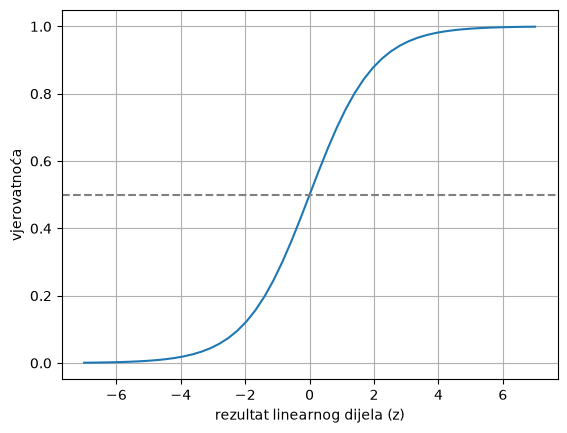

In [68]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-7, 7, 51)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("rezultat linearnog dijela (z)")
plt.ylabel("vjerovatnoća")
plt.grid()
plt.show()

**Pitanje:** šta sigmoid vrati za z = 0? A za jako veliki pozitivni ili negativni z?

In [69]:
# TODO: istrenirajte logističku regresiju
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [70]:
# Vjerovatnoća odlaska za svakog korisnika iz validacije
y_pred = model.predict_proba(X_val)[:, 1]
y_pred[:10].round(2)

array([0.01, 0.2 , 0.21, 0.54, 0.21, 0.21, 0.03, 0.  , 0.58, 0.46])

In [71]:
# TODO: kome šaljemo popust? Svima s vjerovatnoćom >= 0.5
churn_decision = (y_pred >= 0.5).astype(int)

print(f"Accuracy: {(churn_decision == y_val).mean() * 100:.1f} %")

Accuracy: 80.3 %


## 6. Šta je model naučio?

Svaka kolona ima svoju težinu. Pozitivna težina gura vjerovatnoću gore (veći rizik), negativna dolje.

In [72]:
tezine = pd.Series(model.coef_[0], index=dv.get_feature_names_out())
tezine.sort_values().round(3)

contract=two_year                         -0.408
internetservice=dsl                       -0.336
onlinesecurity=yes                        -0.284
multiplelines=no                          -0.258
phoneservice=yes                          -0.250
techsupport=yes                           -0.232
paperlessbilling=no                       -0.231
contract=one_year                         -0.175
partner=no                                -0.166
streamingmovies=no                        -0.121
onlinebackup=no_internet_service          -0.089
techsupport=no_internet_service           -0.089
streamingmovies=no_internet_service       -0.089
internetservice=no                        -0.089
onlinesecurity=no_internet_service        -0.089
deviceprotection=no_internet_service      -0.089
streamingtv=no_internet_service           -0.089
paymentmethod=bank_transfer_(automatic)   -0.087
deviceprotection=yes                      -0.081
onlinebackup=yes                          -0.081
dependents=yes      

**Pitanje:** koja kolona najviše povećava rizik odlaska, a koja ga najviše smanjuje? Slaže li se to s tabelom rizika iz koraka 3?

### Mali model koji možemo izračunati ručno

In [73]:
small = ["contract", "tenure", "monthlycharges"]

dv_small = DictVectorizer(sparse=False)
X_train_small = dv_small.fit_transform(df_train[small].to_dict(orient="records"))

model_small = LogisticRegression()
model_small.fit(X_train_small, y_train)

w0 = model_small.intercept_[0]
w = {k: float(v) for k, v in zip(dv_small.get_feature_names_out(), model_small.coef_[0].round(3))}
print("w0 =", round(w0, 3))
w

w0 = -2.478


{'contract=month-to-month': 0.971,
 'contract=one_year': -0.024,
 'contract=two_year': -0.948,
 'monthlycharges': 0.027,
 'tenure': -0.036}

In [74]:
# TODO: korisnik s ugovorom na dvije godine, 24 mjeseca kod nas, plaća 30 mjesečno.
# Izračunajte z = w0 + težina ugovora + 30 * težina računa + 24 * težina staža, pa sigmoid.
z = w0 + w["contract=two_year"] + 30 * w["monthlycharges"] + 24 * w["tenure"]
print(f"Vjerovatnoća odlaska: {sigmoid(z):.3f}")

Vjerovatnoća odlaska: 0.030


In [75]:
# ⭐ Probajte isto za korisnika s mjesečnim ugovorom, 1 mjesec kod nas, plaća 80 mjesečno
z = w0 + w["contract=month-to-month"] + 80 * w["monthlycharges"] + 1 * w["tenure"]
print(f"Vjerovatnoća odlaska: {sigmoid(z):.3f}")


Vjerovatnoća odlaska: 0.650


## 7. Je li 80 % dobro? (evaluacija)

Accuracy je oko 80 %. Zvuči dobro. Ali uporedimo s modelom koji ništa ne radi.

In [76]:
# TODO: model koji kaže da NIKO ne odlazi. Koliko je tačan?
# Pomoć: np.zeros(n) daje niz od n nula
niko_ne_odlazi = np.zeros(len(y_val))
print(f"Accuracy modela 'niko ne odlazi': {(niko_ne_odlazi == y_val).mean() * 100:.1f} %")

Accuracy modela 'niko ne odlazi': 72.6 %


Naš model je bolji za samo nekoliko procenata. Accuracy ne kaže **gdje** model griješi.

### Matrica konfuzije

In [77]:
stvarno_odlazi = (y_val == 1)
stvarno_ostaje = (y_val == 0)
kaze_odlazi = (y_pred >= 0.5)
kaze_ostaje = (y_pred < 0.5)

tp = (kaze_odlazi & stvarno_odlazi).sum()   # popust dobio onaj ko bi otišao
fp = (kaze_odlazi & stvarno_ostaje).sum()   # popust dobio onaj ko bi ionako ostao
fn = (kaze_ostaje & stvarno_odlazi).sum()   # otišao, a nismo mu ništa ponudili
tn = (kaze_ostaje & stvarno_ostaje).sum()

pd.DataFrame([[tn, fp], [fn, tp]],
             index=["stvarno ostaje", "stvarno odlazi"],
             columns=["model: ostaje", "model: odlazi"])

,model: ostaje,model: odlazi
stvarno ostaje,921,102
stvarno odlazi,176,210


### Precision i recall

In [78]:
# TODO: izračunajte precision i recall
# Precision = TP / (TP + FP),  Recall = TP / (TP + FN)
precision = tp / (tp + fp)
recall = tp / (tp + fn)

print(f"Precision: {precision:.2f}  -> od svih kojima šaljemo popust, toliko bi zaista otišlo")
print(f"Recall:    {recall:.2f}  -> od svih koji odlaze, toliko smo ih uhvatile")

Precision: 0.67  -> od svih kojima šaljemo popust, toliko bi zaista otišlo
Recall:    0.54  -> od svih koji odlaze, toliko smo ih uhvatile


**Diskusija:** šta je skuplje za operatera, popust poslan nekome ko bi ionako ostao (FP) ili korisnik koji ode bez ponude (FN)?

### Prag: kome slati popust?

0.5 nije zakon. Probajmo druge pragove.

In [79]:
for prag in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    odluka = (y_pred >= prag)
    tp = (odluka & stvarno_odlazi).sum()
    fp = (odluka & stvarno_ostaje).sum()
    fn = (~odluka & stvarno_odlazi).sum()
    acc = (odluka == y_val).mean()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    print(f"prag {prag:.1f}: emailova {tp + fp:4d}  uhvaćeno {tp:3d}  propušteno {fn:3d}  "
          f"bespotrebnih popusta {fp:3d}  accuracy {acc:.3f}  precision {precision:.2f}  recall {recall:.2f}")

prag 0.2: emailova  689  uhvaćeno 333  propušteno  53  bespotrebnih popusta 356  accuracy 0.710  precision 0.48  recall 0.86
prag 0.3: emailova  520  uhvaćeno 284  propušteno 102  bespotrebnih popusta 236  accuracy 0.760  precision 0.55  recall 0.74
prag 0.4: emailova  415  uhvaćeno 249  propušteno 137  bespotrebnih popusta 166  accuracy 0.785  precision 0.60  recall 0.65
prag 0.5: emailova  312  uhvaćeno 210  propušteno 176  bespotrebnih popusta 102  accuracy 0.803  precision 0.67  recall 0.54
prag 0.6: emailova  204  uhvaćeno 151  propušteno 235  bespotrebnih popusta  53  accuracy 0.796  precision 0.74  recall 0.39
prag 0.7: emailova   96  uhvaćeno  76  propušteno 310  bespotrebnih popusta  20  accuracy 0.766  precision 0.79  recall 0.20


**Pitanje:** koji prag biste izabrale? Šta se dešava s brojem emailova kad spuštamo prag?

## 8. Završni ispit: test skup

Model treniramo na train + validaciji i jednom provjerimo na testu.

In [80]:
def presicion_score(y_true, y_pred):
    tp = ((y_pred == 1) & (y_true == 1)).sum()
    fp = ((y_pred == 1) & (y_true == 0)).sum()
    return tp / (tp + fp) if (tp + fp) > 0 else 0

def recall_score(y_true, y_pred):
    tp = ((y_pred == 1) & (y_true == 1)).sum()
    fn = ((y_pred == 0) & (y_true == 1)).sum()
    return tp / (tp + fn) if (tp + fn) > 0 else 0

In [81]:
from sklearn.metrics import precision_score


dv = DictVectorizer(sparse=False)
X_full_train = dv.fit_transform(df_full_train[categorical + numerical].to_dict(orient="records"))
y_full_train = df_full_train.churn.values

model = LogisticRegression()
model.fit(X_full_train, y_full_train)

dicts_test = df_test[categorical + numerical].to_dict(orient="records")
X_test = dv.transform(dicts_test)
y_pred_test = model.predict_proba(X_test)[:, 1]

print(f"Accuracy na testu: {((y_pred_test >= 0.5) == y_test).mean() * 100:.1f} %")
print(f"Precision na testu: {precision_score(y_test, y_pred_test >= 0.5):.2f}")
print(f"Recall na testu: {recall_score(y_test, y_pred_test >= 0.5):.2f}")

Accuracy na testu: 81.4 %
Precision na testu: 0.63
Recall na testu: 0.59


In [82]:
# Jedan korisnik iz testa: da li mu šaljemo popust?
korisnik = dicts_test[-1]
print(korisnik)
p = model.predict_proba(dv.transform([korisnik]))[0, 1]
print(f"Vjerovatnoća odlaska: {p:.2f}  ->  {'šaljemo popust' if p >= 0.5 else 'ne šaljemo'}")
print("Stvarno:", "otišao" if y_test[-1] == 1 else "ostao")

{'gender': 'female', 'seniorcitizen': 0, 'partner': 'yes', 'dependents': 'yes', 'phoneservice': 'yes', 'multiplelines': 'yes', 'internetservice': 'fiber_optic', 'onlinesecurity': 'yes', 'onlinebackup': 'no', 'deviceprotection': 'yes', 'techsupport': 'no', 'streamingtv': 'yes', 'streamingmovies': 'yes', 'contract': 'month-to-month', 'paperlessbilling': 'yes', 'paymentmethod': 'electronic_check', 'tenure': 17, 'monthlycharges': 104.2, 'totalcharges': 1743.5}
Vjerovatnoća odlaska: 0.66  ->  šaljemo popust
Stvarno: otišao


---
# ⭐ Bonus 

## Bonus A: koliko novca?

Recimo da popust od 25 % košta operatera **10 KM**, a korisnik koji ode znači gubitak od **100 KM**.
Pretpostavimo da svako ko dobije popust ostane.

In [94]:
#Pogledajte bonus A. Ako popust košta **30 KM**, 
#pa **50 KM** umjesto 10 KM, koji prag je sad najjeftiniji? Objasnite u dvije rečenice zašto se mijenja.
for prag in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    odluka = (y_pred >= prag)
    tp = (odluka & stvarno_odlazi).sum()
    fp = (odluka & stvarno_ostaje).sum()
    fn = (~odluka & stvarno_odlazi).sum()
    trosak = (tp + fp) * 10 + fn * 100
    print(f"prag {prag:.1f}: trošak {trosak:6d} KM")

prag 0.1: trošak  11210 KM
prag 0.2: trošak  12190 KM
prag 0.3: trošak  15400 KM
prag 0.4: trošak  17850 KM
prag 0.5: trošak  20720 KM
prag 0.6: trošak  25540 KM
prag 0.7: trošak  31960 KM


**Pitanje:** koji prag je najjeftiniji? Je li to onaj s najvećim accuracy?

## Bonus B: random forest

Isti podaci, drugi model. Je li bolji?

In [84]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict_proba(X_val)[:, 1]
print(f"Accuracy random forest: {((y_pred_rf >= 0.5) == y_val).mean() * 100:.1f} %")

Accuracy random forest: 79.8 %


## ⭐ Bonus C: cross-validation

Jedna podjela na train i validaciju može biti sreća ili nesreća.
Zato df_full_train podijelimo na 5 dijelova. Svaki dio jednom bude validacija,
a ostala četiri su train. Dobijemo 5 rezultata i gledamo prosjek.

In [87]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
rezultati = []

for train_idx, val_idx in kfold.split(df_full_train):
    d_train = df_full_train.iloc[train_idx]
    d_val = df_full_train.iloc[val_idx]

    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(d_train[categorical + numerical].to_dict(orient="records"))
    X_va = dv.transform(d_val[categorical + numerical].to_dict(orient="records"))

    model = LogisticRegression(max_iter=1000)
    model.fit(X_tr, d_train.churn.values)

    y_p = model.predict_proba(X_va)[:, 1]
    rezultati.append(((y_p >= 0.5) == d_val.churn.values).mean())

print(np.round(rezultati, 3))
print(f"Prosjek: {np.mean(rezultati):.3f}  ±  {np.std(rezultati):.3f}")

[0.804 0.802 0.804 0.79  0.803]
Prosjek: 0.800  ±  0.005


### ⭐ Bonus C2: koji C je najbolji? (hyperparameter tuning)

`C` je hiperparametar logističke regresije: mi ga biramo, model ga ne uči.
Mali C znači oprezniji model s malim težinama, a veliki C daje modelu više slobode.

Za svaku vrijednost C uradimo cross-validation kroz 5 dijelova i uporedimo prosjeke.
Test i dalje ne diramo.

In [88]:
for C in [0.01, 0.1, 1, 10]:
    rezultati = []

    for train_idx, val_idx in kfold.split(df_full_train):
        d_train = df_full_train.iloc[train_idx]
        d_val = df_full_train.iloc[val_idx]

        dv = DictVectorizer(sparse=False)
        X_tr = dv.fit_transform(d_train[categorical + numerical].to_dict(orient="records"))
        X_va = dv.transform(d_val[categorical + numerical].to_dict(orient="records"))

        # TODO: postavite C
        model = LogisticRegression(C=C, max_iter=1000)
        model.fit(X_tr, d_train.churn.values)

        y_p = model.predict_proba(X_va)[:, 1]
        rezultati.append(((y_p >= 0.5) == d_val.churn.values).mean())

    print(f"C = {C:5}:  {np.mean(rezultati):.3f} ± {np.std(rezultati):.3f}")

C =  0.01:  0.802 ± 0.005
C =   0.1:  0.801 ± 0.006
C =     1:  0.800 ± 0.005
C =    10:  0.801 ± 0.005


**Pitanje:** koji C je najbolji? Je li razlika velika u poređenju s rasponom (±)?

Najbolji je C = 0.01. Razlika između najboljeg (0.802) i najgoreg (0.800) rezultata iznosi samo 0.002. Dakle, razlika u poređenju sa rasponom je mala.

---
## 📝 Zadaća

1. Pogledajte bonus A. Ako popust košta **30 KM**, pa **50 KM** umjesto 10 KM, koji prag je sad najjeftiniji? Objasnite u dvije rečenice zašto se mijenja.
2. Izbacite iz modela kolone s najmanjim mutual information (npr. `gender`, `phoneservice`, `multiplelines`). Mijenja li se accuracy na validaciji?

Odgovori:
1. Prag se povećava kako popust postaje veći. Prag se mijenja jer skuplji popust isplati se samo za korisnike koji će vrlo vjerovatno otići, pa moramo tražiti veću vjerovatnoću odlaska prije nego ga ponudimo.

2. Accuracy se blago smanjuje. Te tri kolone pojedinačno nam ne govore ništa o odlasku, tako da i ne donose neko poboljšanje svojim izbacivanjem.

In [95]:
slabe = mi.sort_values().head(3).index.tolist()
print("Izbacujemo:", slabe)

categorical_manje = [c for c in categorical if c not in slabe]


def evaluiraj(kat_kolone, num_kolone):
    kolone = kat_kolone + num_kolone

    dv = DictVectorizer(sparse=False)
    X_tr = dv.fit_transform(df_train[kolone].to_dict(orient="records"))
    X_va = dv.transform(df_val[kolone].to_dict(orient="records"))

    model = LogisticRegression(max_iter=1000)
    model.fit(X_tr, y_train)

    y_p = model.predict_proba(X_va)[:, 1]
    return ((y_p >= 0.5) == y_val).mean()


acc_sve = evaluiraj(categorical, numerical)
acc_manje = evaluiraj(categorical_manje, numerical)

print(f"sve kolone:  {acc_sve:.4f}")
print(f"bez slabih:  {acc_manje:.4f}")
print(f"razlika:     {acc_manje - acc_sve:+.4f}")

Izbacujemo: ['gender', 'phoneservice', 'multiplelines']
sve kolone:  0.8062
bez slabih:  0.8006
razlika:     -0.0057
